# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Alan Ayala  
**Grupo:** __________________  **Fecha:** __________________

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import json

ruta = Path('../data/raw/nyc_taxi_examen.csv')
if not ruta.is_file():
    ruta = Path('data/raw/nyc_taxi_examen.csv')
df = pd.read_csv(ruta)
display(df.head())
print('Dimensiones:', df.shape)
print('Columnas:', df.columns.tolist())
display(df.dtypes.to_frame('Tipo de dato'))
display(df.describe())
print('Tipos de pago:', df['payment_type'].unique())


,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,Credit card,...,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,Credit card,...,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,Credit card,...,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,Credit card,...,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,Credit card,...,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones: (2427612, 21)
Columnas: ['Unnamed: 0', 'VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']


,Tipo de dato
Unnamed: 0,int64
VendorID,int64
tpep_pickup_datetime,str
tpep_dropoff_datetime,str
passenger_count,float64
trip_distance,float64
RatecodeID,float64
PULocationID,float64
DOLocationID,float64
payment_type,str


,Unnamed: 0,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2.427612e+06,2.427612e+06,2.415489e+06,2.415470e+06,2.415474e+06,2.415487e+06,2.415475e+06,2.415488e+06,2.415487e+06,2.415462e+06,2.415459e+06,2.415465e+06,2.415481e+06,2.415484e+06,2.415457e+06,2.415481e+06,2.415462e+06,2.415475e+06
mean,1.213806e+06,1.888167e+00,1.296144e+00,3.300702e+00,4.229419e+00,1.641392e+02,1.632236e+02,3.852567e+01,1.567837e+00,4.849912e-01,3.665195e+00,5.938668e-01,9.873437e-01,2.937731e+01,2.254823e+00,1.979527e-01,5.625318e-01,1.561446e+01
std,7.007914e+05,8.086844e-01,1.881923e+00,5.167909e+00,1.720220e+01,6.285386e+01,6.925613e+01,5.423764e+02,1.906552e+00,1.018682e-01,4.234050e+00,2.385704e+00,1.560490e-01,2.592570e+01,7.815658e-01,6.259005e-01,3.314852e-01,2.605773e+02
min,0.000000e+00,1.000000e+00,-5.000000e+00,-9.998763e+01,1.000000e+00,1.000000e+00,1.000000e+00,-1.849600e+03,-7.500000e+00,-5.000000e-01,-9.000000e+01,-1.064600e+02,-1.000000e+00,-1.866890e+03,-2.500000e+00,-2.000000e+00,-7.500000e-01,-3.005175e+05
25%,6.069028e+05,2.000000e+00,1.000000e+00,9.900000e-01,1.000000e+00,1.320000e+02,1.130000e+02,9.300000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.638000e+01,2.500000e+00,0.000000e+00,7.500000e-01,7.283333e+00
50%,1.213806e+06,2.000000e+00,1.000000e+00,1.700000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.350000e+01,1.000000e+00,5.000000e-01,2.950000e+00,0.000000e+00,1.000000e+00,2.154000e+01,2.500000e+00,0.000000e+00,7.500000e-01,1.231667e+01
75%,1.820708e+06,2.000000e+00,1.000000e+00,3.360000e+00,1.000000e+00,2.320000e+02,2.340000e+02,2.190000e+01,2.500000e+00,5.000000e-01,4.560000e+00,0.000000e+00,1.000000e+00,3.145000e+01,2.500000e+00,0.000000e+00,7.500000e-01,2.011667e+01
max,2.427611e+06,7.000000e+00,1.000000e+02,1.686490e+03,9.900000e+01,2.650000e+02,2.650000e+02,1.999559e+04,2.325000e+01,1.150000e+01,4.444400e+02,6.167900e+02,1.000000e+00,5.530740e+03,2.750000e+00,2.700000e+01,7.500000e-01,8.373667e+03


Tipos de pago: <StringArray>
['Credit card', 'Cash', nan, 'Dispute', 'No charge']
Length: 5, dtype: str


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [2]:
df_limpio = df.copy()
print('Antes:', df_limpio.shape)
display(df_limpio.isna().sum().to_frame('Nulos antes'))
print('Duplicados antes:', df_limpio.duplicated().sum())
df_limpio = df_limpio.drop_duplicates().dropna()
condiciones = (
    (df_limpio['trip_distance'] > 0)
    & (df_limpio['passenger_count'] > 0)
    & (df_limpio['passenger_count'] < 100)
    & (df_limpio['fare_amount'] > 0)
    & (df_limpio['fare_amount'] < 10000)
    & (df_limpio['trip_duration'] > 0)
)
df_limpio = df_limpio.loc[condiciones].copy()
print('Después:', df_limpio.shape)
print('Registros eliminados:', len(df) - len(df_limpio))


Antes: (2427612, 21)


,Nulos antes
Unnamed: 0,0
VendorID,0
tpep_pickup_datetime,12126
tpep_dropoff_datetime,12127
passenger_count,12123
trip_distance,12142
RatecodeID,12138
PULocationID,12125
DOLocationID,12137
payment_type,12125


Duplicados antes: 0


Después: (2107024, 21)
Registros eliminados: 320588


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [3]:
df_cash = df_limpio.loc[df_limpio['payment_type'] == 'Cash'].copy()
X = df_cash[['trip_distance', 'trip_duration']].copy()
print('Viajes pagados en efectivo:', len(df_cash))
display(X.describe())


Viajes pagados en efectivo: 283537


,trip_distance,trip_duration
count,283537.000000,283537.000000
mean,3.842333,17.508951
std,6.210980,40.704348
min,0.010000,0.033333
25%,0.920000,7.400000
50%,1.700000,12.416667
75%,4.370000,20.883333
max,1686.490000,8373.666667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [4]:
X_log = np.log1p(X)
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_log)
print('Variables con log1p:')
display(X_log.describe())
print('Variables estandarizadas:')
display(pd.DataFrame(X_escalado, columns=X.columns).describe())


Variables con log1p:


,trip_distance,trip_duration
count,283537.000000,283537.000000
mean,1.225452,2.607564
std,0.763307,0.744480
min,0.009950,0.032790
25%,0.652325,2.128232
50%,0.993252,2.596498
75%,1.680828,3.085725
max,7.430997,9.032967


Variables estandarizadas:


,trip_distance,trip_duration
count,2.835370e+05,2.835370e+05
mean,1.395339e-16,3.247771e-17
std,1.000002e+00,1.000002e+00
min,-1.592418e+00,-3.458494e+00
25%,-7.508485e-01,-6.438498e-01
50%,-3.042034e-01,-1.486448e-02
75%,5.965843e-01,6.422769e-01
max,8.129834e+00,8.630743e+00


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

k=2: inercia=228854.78, silueta=0.5260


k=3: inercia=138246.48, silueta=0.4474


k=4: inercia=101160.36, silueta=0.4108


k=5: inercia=79653.89, silueta=0.3944


k=6: inercia=67332.57, silueta=0.3724


,k,Inercia,Silueta
0,2,228854.781875,0.526003
1,3,138246.477164,0.447359
2,4,101160.355955,0.410762
3,5,79653.892836,0.394423
4,6,67332.568154,0.372353


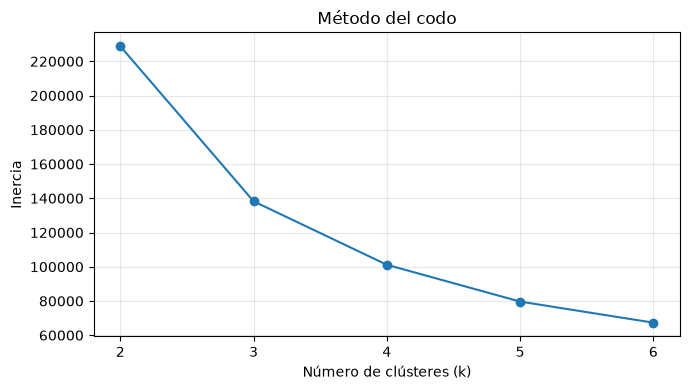

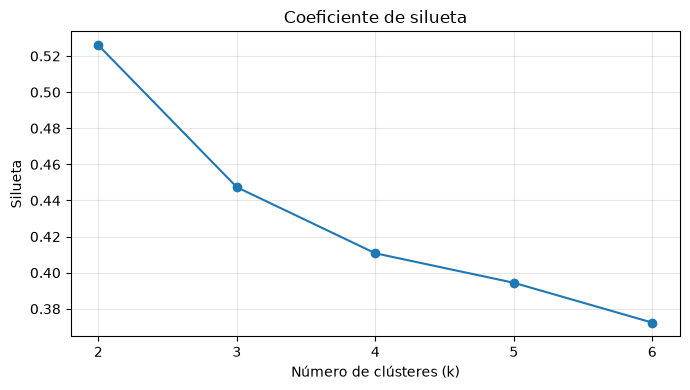

In [5]:
resultados = []
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo.fit_predict(X_escalado)
    silueta = silhouette_score(X_escalado, etiquetas_k, sample_size=5000, random_state=42)
    resultados.append({'k': k, 'Inercia': modelo.inertia_, 'Silueta': silueta})
    print(f'k={k}: inercia={modelo.inertia_:.2f}, silueta={silueta:.4f}')
tabla_metricas = pd.DataFrame(resultados)
display(tabla_metricas)

plt.figure(figsize=(7, 4))
plt.plot(tabla_metricas['k'], tabla_metricas['Inercia'], marker='o')
plt.title('Método del codo')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia')
plt.xticks(range(2, 7))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(tabla_metricas['k'], tabla_metricas['Silueta'], marker='o')
plt.title('Coeficiente de silueta')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Silueta')
plt.xticks(range(2, 7))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

k elegido: 2


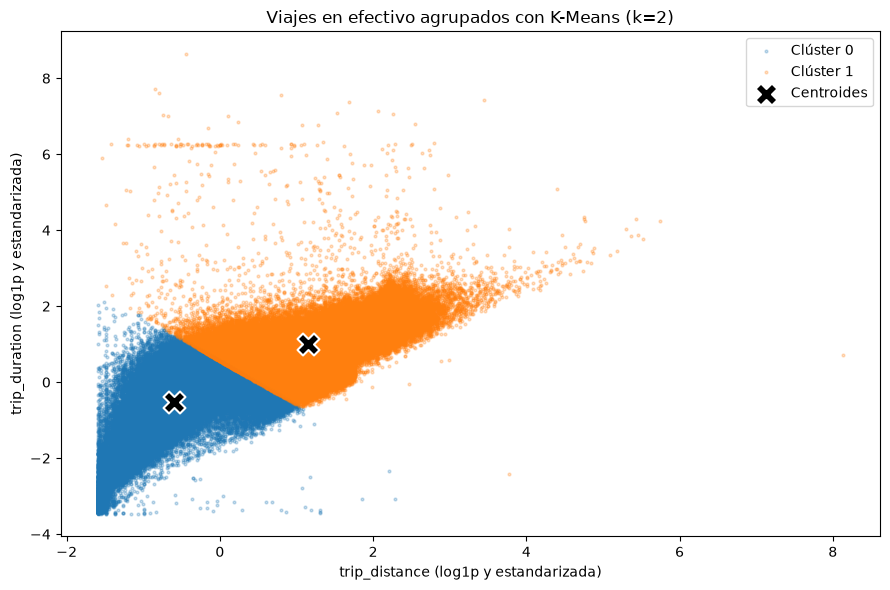

In [6]:
# Se elige la mayor silueta y se revisa la inercia y el perfil de los grupos.
k_elegido = int(tabla_metricas.loc[tabla_metricas['Silueta'].idxmax(), 'k'])
print('k elegido:', k_elegido)
modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
etiquetas = modelo_final.fit_predict(X_escalado)

plt.figure(figsize=(9, 6))
for grupo in range(k_elegido):
    puntos = X_escalado[etiquetas == grupo]
    plt.scatter(puntos[:, 0], puntos[:, 1], s=4, alpha=0.25,
                label=f'Clúster {grupo}', rasterized=True)
centroides = modelo_final.cluster_centers_
plt.scatter(centroides[:, 0], centroides[:, 1], marker='X', s=250,
            color='black', edgecolors='white', linewidths=1.5, label='Centroides')
plt.title(f'Viajes en efectivo agrupados con K-Means (k={k_elegido})')
plt.xlabel('trip_distance (log1p y estandarizada)')
plt.ylabel('trip_duration (log1p y estandarizada)')
plt.legend()
plt.tight_layout()
plt.show()


## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [7]:
df_resultado = df_cash.copy()
df_resultado['cluster'] = etiquetas
tabla_clusters = df_resultado.groupby('cluster').agg(
    cantidad_viajes=('cluster', 'size'),
    distancia_media_millas=('trip_distance', 'mean'),
    distancia_mediana_millas=('trip_distance', 'median'),
    duracion_media_minutos=('trip_duration', 'mean'),
    duracion_mediana_minutos=('trip_duration', 'median')
)
display(tabla_clusters.round(2))


,cantidad_viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_minutos,duracion_mediana_minutos
cluster,,,,,
0,187187,1.28,1.13,9.52,8.95
1,96350,8.81,7.05,33.04,25.83


**Parte B. Preguntas de análisis**

**1. ¿Qué valor de k elegiste y por qué?**

Elegí **k = 2** porque tuvo la mejor silueta (**0.526**). La inercia fue de **228,854.78** y bajó a **138,246.48** con k = 3, pero la silueta también bajó a **0.447**. Por eso preferí dos grupos fáciles de interpretar: viajes cortos y largos.

**2. Describe cada clúster y dale un nombre.**

- **Clúster 0: viajes cortos.** Tiene **187,187 viajes**, con un promedio de **1.28 millas** y **9.52 minutos**. Sus medianas son **1.13 millas** y **8.95 minutos**, así que suelen ser recorridos cortos y rápidos.
- **Clúster 1: viajes largos.** Tiene **96,350 viajes**, con un promedio de **8.81 millas** y **33.04 minutos**. Sus medianas son **7.05 millas** y **25.83 minutos**. Las medias son mayores que las medianas, lo que sugiere que algunos viajes muy largos suben el promedio.

**3. ¿Qué clúster tiene la mayor duración promedio? ¿También la mayor distancia?**

El **clúster 1**, con **33.04 minutos**. También tiene la mayor distancia promedio: **8.81 millas**, frente a **1.28 millas** del clúster 0.

**4. ¿Cuál es el grupo más numeroso y cómo son sus viajes?**

El **clúster 0**, con **187,187 viajes**. Predominan los recorridos cortos, con un promedio de **1.28 millas** y **9.52 minutos**.


---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**